In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("scikit-learn:", sklearn.__version__)

In [ ]:
df1 = pd.DataFrame({
    "income" : [20000,30000,400000,50000],
    "loan_amount" : [10000,15000,40000,20000],
    "defaulted" : [0,1,0,0]
})
print(df1)
print(df1.shape)
print(df1['defaulted'].value_counts())

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving cs-training.csv.zip to cs-training.csv.zip


In [ ]:
!unzip -o cs-training.csv.zip

Archive:  cs-training.csv.zip
  inflating: cs-training.csv         


In [ ]:
import pandas as pd

# We can read the CSV directly from the uploaded ZIP archive
try:
    df = pd.read_csv("cs-training.csv (1).zip", index_col=0)
except FileNotFoundError:
    # Fallback to the original name if ' (1)' is not in the filename
    df = pd.read_csv("cs-training.csv.zip", index_col=0)

print(df.shape)
df.head()

(150000, 11)


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 150000 entries, 1 to 150000
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float64
dtypes: fl

In [ ]:
df.describe()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,1.202690e+05,150000.000000,150000.000000,150000.000000,150000.000000,146076.000000
mean,0.066840,6.048438,52.295207,0.421033,353.005076,6.670221e+03,8.452760,0.265973,1.018240,0.240387,0.757222
std,0.249746,249.755371,14.771866,4.192781,2037.818523,1.438467e+04,5.145951,4.169304,1.129771,4.155179,1.115086
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.029867,41.000000,0.000000,0.175074,3.400000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.154181,52.000000,0.000000,0.366508,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,0.000000,0.559046,63.000000,0.000000,0.868254,8.249000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,1.000000,50708.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,20.000000


In [ ]:
df.isnull().sum()

,0
SeriousDlqin2yrs,0
RevolvingUtilizationOfUnsecuredLines,0
age,0
NumberOfTime30-59DaysPastDueNotWorse,0
DebtRatio,0
MonthlyIncome,29731
NumberOfOpenCreditLinesAndLoans,0
NumberOfTimes90DaysLate,0
NumberRealEstateLoansOrLines,0
NumberOfTime60-89DaysPastDueNotWorse,0


In [ ]:
print((df["age"] < 18).sum())

1


In [ ]:
# 2. What are the biggest values in the "90 days late" column?
df["NumberOfTimes90DaysLate"].value_counts().sort_index().tail(5)

,count
NumberOfTimes90DaysLate,
14,2
15,2
17,1
96,5
98,264


In [ ]:
# 3. How many have utilization above 1, and DebtRatio above 1?
print((df["RevolvingUtilizationOfUnsecuredLines"] > 1).sum())
print((df["DebtRatio"] > 1).sum())

3321
35137


In [ ]:
# 4. Are the high DebtRatio rows the ones with missing income?
df[df["DebtRatio"] > 1]["MonthlyIncome"].isnull().mean()

np.float64(0.7941486182656459)

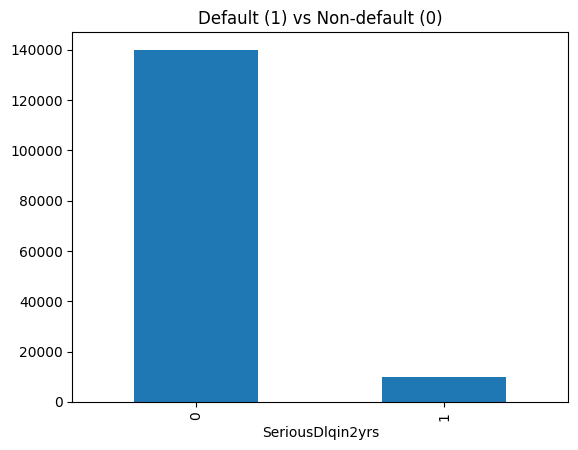

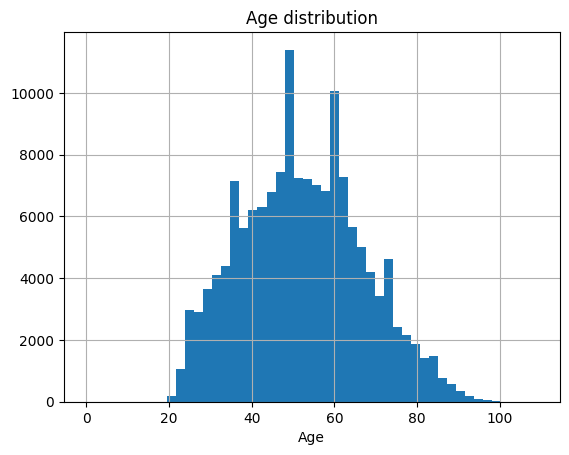

In [ ]:
import matplotlib.pyplot as plt

# Default vs non-default counts
df["SeriousDlqin2yrs"].value_counts().plot(kind="bar")
plt.title("Default (1) vs Non-default (0)")
plt.show()

# Age distribution
df["age"].hist(bins=50)
plt.title("Age distribution")
plt.xlabel("Age")
plt.show()

In [ ]:
# Remove the impossible age
df = df[df["age"] >= 18].copy()

# Flag rows with placeholder codes, then replace the codes with 0
late_cols = ["NumberOfTime30-59DaysPastDueNotWorse",
             "NumberOfTime60-89DaysPastDueNotWorse",
             "NumberOfTimes90DaysLate"]
df["late_code_flag"] = (df[late_cols] >= 96).any(axis=1).astype(int)
for c in late_cols:
    df.loc[df[c] >= 96, c] = 0

# Flag missing income
df["income_missing"] = df["MonthlyIncome"].isnull().astype(int)

In [ ]:
print(df.groupby("late_code_flag")["SeriousDlqin2yrs"].mean())
print(df.groupby("income_missing")["SeriousDlqin2yrs"].mean())

late_code_flag
0    0.065979
1    0.546468
Name: SeriousDlqin2yrs, dtype: float64
income_missing
0    0.069486
1    0.056137
Name: SeriousDlqin2yrs, dtype: float64


In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="SeriousDlqin2yrs")
y = df["SeriousDlqin2yrs"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
X_train = X_train.copy()
X_test = X_test.copy()

In [ ]:
income_median = X_train["MonthlyIncome"].median()
dep_median = X_train["NumberOfDependents"].median()
caps = {c: X_train[c].quantile(0.99) for c in
        ["RevolvingUtilizationOfUnsecuredLines", "DebtRatio", "MonthlyIncome"]}

for part in (X_train, X_test):
    part["MonthlyIncome"] = part["MonthlyIncome"].fillna(income_median)
    part["NumberOfDependents"] = part["NumberOfDependents"].fillna(dep_median)
    for c, cap in caps.items():
        part[c] = part[c].clip(upper=cap)

In [ ]:
print(X_train.shape, X_test.shape)
print(X_train.isnull().sum().sum(), X_test.isnull().sum().sum())
print(y_train.mean(), y_test.mean())
X_train.describe().loc[["min", "max"]]

(119999, 12) (30000, 12)
0 0
0.06684222368519738 0.06683333333333333


,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,late_code_flag,income_missing
min,0.000000,21.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,1.095907,109.0,13.0,4983.04,25000.0,58.0,17.0,54.0,11.0,20.0,1.0,1.0


In [ ]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

skewed = ["RevolvingUtilizationOfUnsecuredLines", "DebtRatio", "MonthlyIncome"]

Xtr = X_train.copy()
Xte = X_test.copy()
for c in skewed:
    Xtr[c] = np.log1p(Xtr[c])
    Xte[c] = np.log1p(Xte[c])

scaler = StandardScaler().fit(Xtr)
Xtr_s = scaler.transform(Xtr)
Xte_s = scaler.transform(Xte)

lr = LogisticRegression(max_iter=1000)
lr.fit(Xtr_s, y_train)

pred = lr.predict(Xte_s)
proba = lr.predict_proba(Xte_s)[:, 1]

print(classification_report(y_test, pred, digits=3))
print("ROC-AUC:", roc_auc_score(y_test, proba))
print(confusion_matrix(y_test, pred))

              precision    recall  f1-score   support

           0      0.944     0.991     0.967     27995
           1      0.583     0.172     0.265      2005

    accuracy                          0.936     30000
   macro avg      0.763     0.581     0.616     30000
weighted avg      0.919     0.936     0.920     30000

ROC-AUC: 0.8547489287141139
[[27749   246]
 [ 1661   344]]


In [ ]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

def evaluate(name, pred, proba):
    return {"model": name,
            "precision": precision_score(y_test, pred),
            "recall": recall_score(y_test, pred),
            "f1": f1_score(y_test, pred),
            "roc_auc": roc_auc_score(y_test, proba)}

results = [evaluate("Baseline LR", pred, proba)]

In [ ]:
lr_w = LogisticRegression(max_iter=1000, class_weight="balanced")
lr_w.fit(Xtr_s, y_train)
pred_w = lr_w.predict(Xte_s)
proba_w = lr_w.predict_proba(Xte_s)[:, 1]
results.append(evaluate("LR + class weights", pred_w, proba_w))

In [ ]:
!pip install -q imbalanced-learn
from imblearn.over_sampling import SMOTE

sm = SMOTE(random_state=42)
Xtr_sm, ytr_sm = sm.fit_resample(Xtr_s, y_train)

lr_sm = LogisticRegression(max_iter=1000).fit(Xtr_sm, ytr_sm)
pred_sm = lr_sm.predict(Xte_s)
proba_sm = lr_sm.predict_proba(Xte_s)[:, 1]
results.append(evaluate("LR + SMOTE", pred_sm, proba_sm))

In [ ]:
for t in [0.5, 0.4, 0.3, 0.2, 0.15, 0.1]:
    p = (proba >= t).astype(int)
    print(f"threshold {t}: precision {precision_score(y_test, p):.3f}, recall {recall_score(y_test, p):.3f}")

threshold 0.5: precision 0.583, recall 0.172
threshold 0.4: precision 0.550, recall 0.226
threshold 0.3: precision 0.506, recall 0.297
threshold 0.2: precision 0.443, recall 0.409
threshold 0.15: precision 0.386, recall 0.514
threshold 0.1: precision 0.262, recall 0.664


In [ ]:
pd.DataFrame(results).round(3)

,model,precision,recall,f1,roc_auc
0,Baseline LR,0.583,0.172,0.265,0.855
1,LR + class weights,0.217,0.757,0.337,0.860
2,LR + SMOTE,0.214,0.759,0.334,0.859


In [ ]:
from sklearn.metrics import average_precision_score

def evaluate2(name, pred, proba):
    return {"model": name,
            "precision": precision_score(y_test, pred),
            "recall": recall_score(y_test, pred),
            "f1": f1_score(y_test, pred),
            "roc_auc": roc_auc_score(y_test, proba),
            "pr_auc": average_precision_score(y_test, proba)}

# re-score the logistic models with the new helper
results2 = [
    evaluate2("Baseline LR", pred, proba),
    evaluate2("LR + class weights", pred_w, proba_w),
]

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=300, min_samples_leaf=20,
    class_weight="balanced_subsample", n_jobs=-1, random_state=42
)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)
proba_rf = rf.predict_proba(X_test)[:, 1]
results2.append(evaluate2("Random Forest", pred_rf, proba_rf))

In [ ]:
from xgboost import XGBClassifier

ratio = (y_train == 0).sum() / (y_train == 1).sum()

xgb = XGBClassifier(
    n_estimators=400, learning_rate=0.05, max_depth=4,
    subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=ratio, eval_metric="auc",
    n_jobs=-1, random_state=42
)
xgb.fit(X_train, y_train)
pred_xgb = xgb.predict(X_test)
proba_xgb = xgb.predict_proba(X_test)[:, 1]
results2.append(evaluate2("XGBoost", pred_xgb, proba_xgb))

In [ ]:
pd.DataFrame(results2).round(3)

,model,precision,recall,f1,roc_auc,pr_auc
0,Baseline LR,0.583,0.172,0.265,0.855,0.379
1,LR + class weights,0.217,0.757,0.337,0.860,0.383
2,Random Forest,0.281,0.673,0.396,0.865,0.388
3,XGBoost,0.221,0.774,0.344,0.869,0.398


In [ ]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from xgboost import XGBClassifier

param_dist = {
    "n_estimators": [200, 300, 400, 600],
    "learning_rate": [0.02, 0.03, 0.05, 0.08],
    "max_depth": [3, 4, 5, 6],
    "min_child_weight": [1, 5, 10, 20],
    "subsample": [0.7, 0.8, 0.9],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "gamma": [0, 1, 5],
}

base = XGBClassifier(scale_pos_weight=ratio, eval_metric="auc",
                     n_jobs=-1, random_state=42)

search = RandomizedSearchCV(
    base, param_dist, n_iter=20, scoring="average_precision",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    random_state=42, n_jobs=1, verbose=1
)
search.fit(X_train, y_train)

print(search.best_params_)
print("CV PR-AUC:", search.best_score_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
{'subsample': 0.8, 'n_estimators': 600, 'min_child_weight': 10, 'max_depth': 5, 'learning_rate': 0.02, 'gamma': 0, 'colsample_bytree': 0.6}
CV PR-AUC: 0.4008348012549178


In [ ]:
best = search.best_estimator_
proba_best = best.predict_proba(X_test)[:, 1]
pred_best = best.predict(X_test)
results2.append(evaluate2("XGBoost tuned", pred_best, proba_best))
pd.DataFrame(results2).round(3)

,model,precision,recall,f1,roc_auc,pr_auc
0,Baseline LR,0.583,0.172,0.265,0.855,0.379
1,LR + class weights,0.217,0.757,0.337,0.860,0.383
2,Random Forest,0.281,0.673,0.396,0.865,0.388
3,XGBoost,0.221,0.774,0.344,0.869,0.398
4,XGBoost tuned,0.222,0.774,0.345,0.870,0.400


In [ ]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold

oof = cross_val_predict(
    best, X_train, y_train,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    method="predict_proba"
)[:, 1]

In [ ]:
COST_FN = 5   # assumption: a missed defaulter costs 5x a wrongly rejected good borrower
COST_FP = 1

thresholds = np.arange(0.05, 0.96, 0.01)
costs = []
for t in thresholds:
    p = oof >= t
    fn = ((~p) & (y_train == 1)).sum()
    fp = (p & (y_train == 0)).sum()
    costs.append(fn * COST_FN + fp * COST_FP)

thr = thresholds[int(np.argmin(costs))]
print("Chosen threshold:", round(thr, 2))

Chosen threshold: 0.71


In [ ]:
final_pred = (proba_best >= thr).astype(int)

print(classification_report(y_test, final_pred, digits=3))
print(confusion_matrix(y_test, final_pred))
print("ROC-AUC:", roc_auc_score(y_test, proba_best))

              precision    recall  f1-score   support

           0      0.968     0.926     0.947     27995
           1      0.358     0.579     0.443      2005

    accuracy                          0.903     30000
   macro avg      0.663     0.752     0.695     30000
weighted avg      0.928     0.903     0.913     30000

[[25919  2076]
 [  845  1160]]
ROC-AUC: 0.8699594022623383


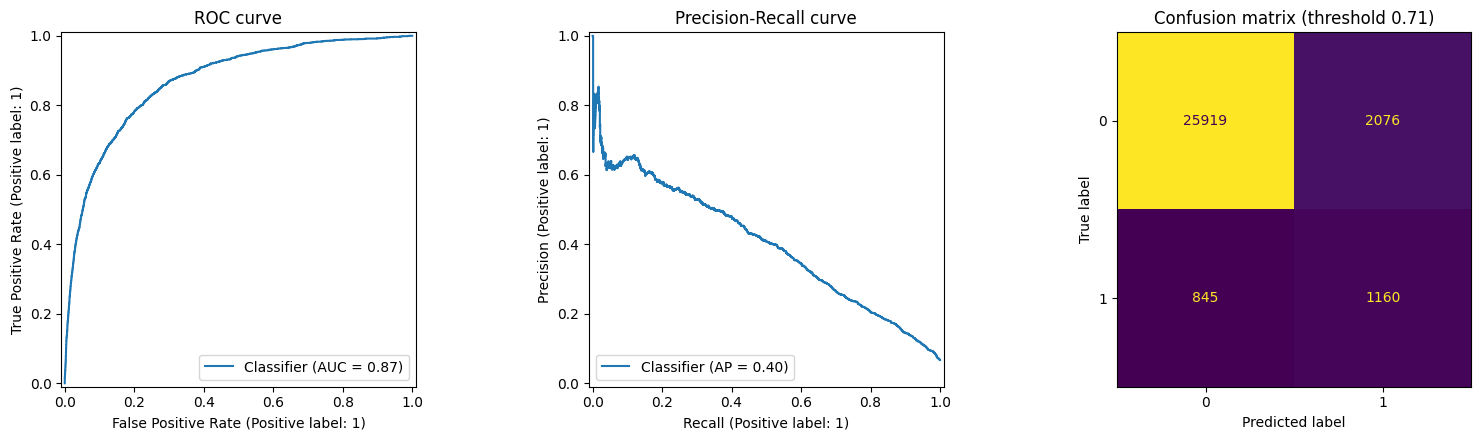

In [ ]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
RocCurveDisplay.from_predictions(y_test, proba_best, ax=ax[0])
ax[0].set_title("ROC curve")
PrecisionRecallDisplay.from_predictions(y_test, proba_best, ax=ax[1])
ax[1].set_title("Precision-Recall curve")
ConfusionMatrixDisplay.from_predictions(y_test, final_pred, ax=ax[2], colorbar=False)
ax[2].set_title(f"Confusion matrix (threshold {thr:.2f})")
plt.tight_layout()
plt.savefig("evaluation.png", dpi=150)
plt.show()

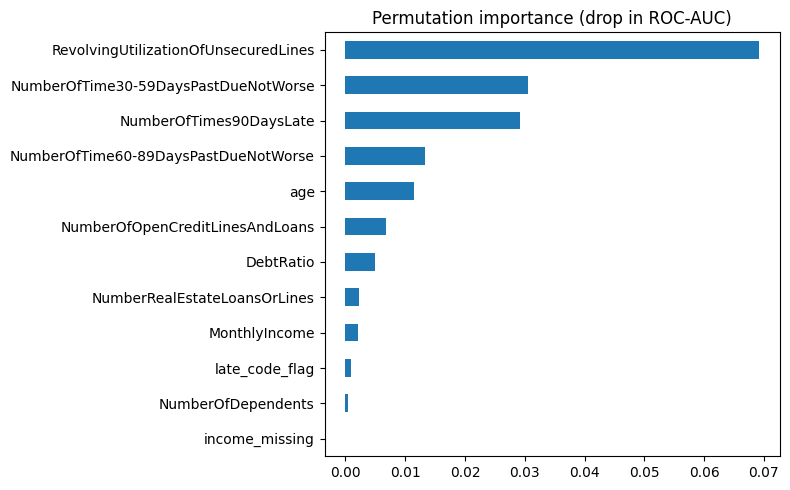

RevolvingUtilizationOfUnsecuredLines    0.0692
NumberOfTime30-59DaysPastDueNotWorse    0.0306
NumberOfTimes90DaysLate                 0.0292
NumberOfTime60-89DaysPastDueNotWorse    0.0134
age                                     0.0115
NumberOfOpenCreditLinesAndLoans         0.0068
DebtRatio                               0.0049
NumberRealEstateLoansOrLines            0.0023
MonthlyIncome                           0.0020
late_code_flag                          0.0009
NumberOfDependents                      0.0004
income_missing                         -0.0000
dtype: float64


In [ ]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(best, X_test, y_test, scoring="roc_auc",
                              n_repeats=5, random_state=42, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

imp.plot(kind="barh", figsize=(8, 5))
plt.title("Permutation importance (drop in ROC-AUC)")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150)
plt.show()
print(imp.sort_values(ascending=False).round(4))

In [ ]:
import joblib
from google.colab import files

joblib.dump({
    "model": best,
    "columns": list(X_train.columns),
    "income_median": income_median,
    "dep_median": dep_median,
    "caps": caps,
    "threshold": float(thr),
}, "loan_model.joblib")

files.download("loan_model.joblib")
files.download("evaluation.png")
files.download("feature_importance.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip install -q streamlit

import joblib
import pandas as pd
import streamlit as st

art = joblib.load("loan_model.joblib")
model, cols, caps, thr = art["model"], art["columns"], art["caps"], art["threshold"]

st.set_page_config(page_title="Loan Default Risk", page_icon="Ἶ6")
st.title("Loan Default Risk Estimator")
st.caption("Demo built on the 'Give Me Some Credit' dataset. For learning only, not financial advice.")

c1, c2 = st.columns(2)
with c1:
    age = st.number_input("Age", 18, 110, 40)
    income_known = st.checkbox("Monthly income is known", value=True)
    income = st.number_input("Monthly income", 0, 1_000_000, 5000, disabled=not income_known)
    dependents = st.number_input("Number of dependents", 0, 20, 0)
    open_lines = st.number_input("Open credit lines and loans", 0, 60, 8)
    real_estate = st.number_input("Real estate loans", 0, 60, 1)
with c2:
    util = st.number_input("Credit utilization (balance / limit)", 0.0, 10.0, 0.3, step=0.05)
    debt_ratio = st.number_input("Debt ratio (monthly debt / income)", 0.0, 5000.0, 0.4, step=0.05)
    late30 = st.number_input("Times 30-59 days late", 0, 20, 0)
    late60 = st.number_input("Times 60-89 days late", 0, 20, 0)
    late90 = st.number_input("Times 90+ days late", 0, 20, 0)

if st.button("Estimate risk", type="primary"):
    row = {
        "RevolvingUtilizationOfUnsecuredLines": min(util, caps["RevolvingUtilizationOfUnsecuredLines"]),
        "age": age,
        "NumberOfTime30-59DaysPastDueNotWorse": late30,
        "DebtRatio": min(debt_ratio, caps["DebtRatio"]),
        "MonthlyIncome": min(income if income_known else art["income_median"], caps["MonthlyIncome"]),
        "NumberOfOpenCreditLinesAndLoans": open_lines,
        "NumberOfTimes90DaysLate": late90,
        "NumberRealEstateLoansOrLines": real_estate,
        "NumberOfTime60-89DaysPastDueNotWorse": late60,
        "NumberOfDependents": dependents,
        "late_code_flag": 0,
        "income_missing": 0 if income_known else 1,
    }
    X = pd.DataFrame([row])[cols]
    score = float(model.predict_proba(X)[:, 1][0])

    if score >= thr:
        band = "High risk"
        st.error(band)
    elif score >= thr / 2:
        band = "Medium risk"
        st.warning(band)
    else:
        band = "Low risk"
        st.success(band)

    st.metric("Risk score", f"{score:.2f}")
    st.caption(f"The score ranks borrowers by risk; it is not a literal probability. "
               f"Scores of {thr:.2f} or higher are flagged as high risk.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 92.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 81.8 MB/s eta 0:00:00


2026-10-11 10:32:31.474 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-11 10:32:31.475 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-11 10:32:31.642 
  command:

    streamlit run /usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2026-10-11 10:32:31.643 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-11 10:32:31.644 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-11 10:32:31.645 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-11 10:32:31.646 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when runn

In [ ]:
!ls -lh *.joblib *.png

-rw-r--r-- 1 root root  92K Oct 11 10:31 evaluation.png
-rw-r--r-- 1 root root  80K Oct 11 10:32 feature_importance.png
-rw-r--r-- 1 root root 1.5M Oct 11 10:32 loan_model.joblib


In [ ]:
from google.colab import files
files.download("loan_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download("feature_importance.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

ValueError: Mountpoint must not already contain files

In [ ]:
!mkdir -p "/content/drive/MyDrive/loan-default-app"
!cp loan_model.joblib evaluation.png feature_importance.png "/content/drive/MyDrive/loan-default-app/"
!ls -lh "/content/drive/MyDrive/loan-default-app/"

total 1.7M
-rw-r--r-- 1 root root  92K Oct 11 10:35 evaluation.png
-rw-r--r-- 1 root root  80K Oct 11 10:35 feature_importance.png
-rw-r--r-- 1 root root 1.5M Oct 11 10:35 loan_model.joblib


In [50]:
import json

best.save_model("xgb_model.json")

meta = {
    "columns": list(X_train.columns),
    "income_median": float(income_median),
    "dep_median": float(dep_median),
    "caps": {k: float(v) for k, v in caps.items()},
    "threshold": float(thr),
}
with open("meta.json", "w") as f:
    json.dump(meta, f)

In [49]:
!cp xgb_model.json meta.json "/content/drive/MyDrive/loan-default-app/"